# Feature engineering

Which information is available when a prediction is made? Start with fixed calendar geometry and lagged observations.

**Development notebook.** Expand the library cells to edit the implementation. Examples below use local data and CPU. [Build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp features

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
plt.style.use('default')
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110,
    'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})

## Build `features`

### Imports and configuration

In [3]:
#| export features
from __future__ import annotations

from collections.abc import Sequence
from numpy.typing import ArrayLike, NDArray

import numpy as np
import pandas as pd
from timegym._internal import _real_array


### Shared integer validation

In [4]:
#| export features
from timegym._internal import positive_int, nonnegative_int


### add_lagged_target

In [5]:
#| export features
def add_lagged_target(
    df: pd.DataFrame, lags: int = 10, dropna: bool = True
) -> pd.DataFrame:
    """Append previous observations as {column}_t-{lag} in column-major order.

    The original columns remain unchanged; exclude the current target from a
    contemporaneous predictor matrix. Lags count rows, not calendar durations.
    dropna=True removes rows missing any original or generated value; False
    retains the original index and the missing warmup values. Zero lags adds
    no columns. The input is never mutated and name collisions raise.
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame")
    if not df.columns.is_unique:
        raise ValueError("df columns must be unique")
    lags = nonnegative_int(lags, "lags")
    df = df.copy()
    for col in df.columns:
        for lag in range(1, 1 + lags):
            name = f"{col}_t-{lag}"
            if name in df.columns:
                raise ValueError(f"Lagged feature column already exists: {name}")
            df[name] = df[col].shift(lag)
    return df.dropna() if dropna else df


### cyclical_encoding — Return cosine/sine features using a fixed cycle and phase origin.

In [6]:
#| export features
def cyclical_encoding(
    values: ArrayLike,
    scaled: bool = False,
    min_value: float | None = None,
    max_value: float | None = None,
    *,
    period: float | None = None,
) -> tuple[NDArray[np.float64], NDArray[np.float64]]:
    """Return cosine/sine features using a fixed cycle and phase origin.

    Prefer period=7, min_value=0 for weekdays and period=24 for hours.
    Explicit bounds denote inclusive discrete labels, so bounds 0..6
    imply period 7. The period is never estimated from the observed sample.
    With scaled=True, values already express fractions of a full cycle.
    """
    values = _real_array(values, "cyclical values")
    if not np.isfinite(values).all():
        raise ValueError("cyclical values must be finite")
    if scaled:
        if any(value is not None for value in (min_value, max_value, period)):
            raise ValueError("scaled values cannot also specify bounds or a period")
        phase = values
    else:
        origin = 0.0 if min_value is None else float(min_value)
        if period is not None and max_value is not None:
            raise ValueError("Specify period or inclusive max_value, not both")
        if period is None:
            if max_value is None:
                raise ValueError(
                    "Supply an explicit period or inclusive min_value/max_value bounds"
                )
            period = float(max_value) - origin + 1.0
        period = float(period)
        if not np.isfinite(origin) or not np.isfinite(period) or period <= 0:
            raise ValueError(
                "The cycle origin must be finite and period must be positive"
            )
        phase = (values - origin) / period
    return np.asarray(np.cos(phase * 2 * np.pi)), np.asarray(np.sin(phase * 2 * np.pi))


### add_time_features — Add a stable calendar-feature schema to a DatetimeIndex dataframe.

In [7]:
#| export features
def add_time_features(df: pd.DataFrame) -> pd.DataFrame:
    """Add a stable calendar-feature schema to a DatetimeIndex dataframe.

    Calendar fields use local clock time. 'time' is elapsed days since the
    Unix epoch (UTC for timezone-aware indexes), with no sample-fitted scaling.
    A fixed schema keeps separate training and prediction slices compatible.
    Preserve the input columns and index; reject generated-name collisions.
    No statistic is fitted on the sample and the input is never mutated.
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame")
    if not df.columns.is_unique:
        raise ValueError("df columns must be unique")
    if not isinstance(df.index, pd.DatetimeIndex) or df.index.hasnans:
        raise ValueError("add_time_features requires a DatetimeIndex without NaT")
    components_names = (
        "quarter",
        "month",
        "day",
        "weekday",
        "hour",
        "minute",
        "second",
        "microsecond",
        "day_adj",
    )
    generated = {"time", "year"} | {
        f"{name}_{part}" for name in components_names for part in ("cos", "sin")
    }
    collisions = [name for name in df.columns if name in generated]
    if collisions:
        raise ValueError(f"Calendar feature columns already exist: {collisions}")
    df = df.copy()
    index = df.index
    epoch = pd.Timestamp("1970-01-01", tz="UTC" if index.tz is not None else None)
    df["time"] = (index - epoch).total_seconds() / 86400.0
    df["year"] = index.year
    components = (
        ("quarter", index.quarter, 4, 1),
        ("month", index.month, 12, 1),
        ("day", index.day, 31, 1),
        ("weekday", index.day_of_week, 7, 0),
        ("hour", index.hour, 24, 0),
        ("minute", index.minute, 60, 0),
        ("second", index.second, 60, 0),
        ("microsecond", index.microsecond, 1_000_000, 0),
    )
    for name, values, period, origin in components:
        df[f"{name}_cos"], df[f"{name}_sin"] = cyclical_encoding(
            values, period=period, min_value=origin
        )
    fraction_of_month = (index.day - 1) / index.days_in_month
    df["day_adj_cos"], df["day_adj_sin"] = cyclical_encoding(
        fraction_of_month, scaled=True
    )
    return df


### add_tsfel_features — Extract rolling features without importing TSFEL until it is requested.

In [8]:
#| export features
def add_tsfel_features(
    df: pd.DataFrame,
    use_cols: str | Sequence[str] | None = None,
    window_size: int = 100,
    domain: str | None = None,
    frequency: float = 100,
    dropna: bool = True,
    show_progress: bool = False,
    lag: int = 1,
) -> pd.DataFrame:
    """Extract rolling features without importing TSFEL until it is requested.

    At output row t the last window observation is t-lag. Thus the default
    lag=1 excludes the current row; lag=0 includes it. Row counts define windows;
    frequency is the sampling frequency in Hz passed to TSFEL. Install
    timegym[features] to use this helper. Return selected original columns plus
    extracted columns at the original index, without mutating the input.
    dropna=True removes rows missing any selected or extracted value; False
    keeps warmup rows with missing features. Name collisions raise.
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame")
    if not df.columns.is_unique:
        raise ValueError("df columns must be unique")
    window_size = positive_int(window_size, "window_size")
    lag = nonnegative_int(lag, "lag")
    if not np.isfinite(frequency) or frequency <= 0:
        raise ValueError("frequency must be positive and finite")
    first_row = window_size + lag - 1
    if len(df) <= first_row:
        raise ValueError("Insufficient rows for the requested window_size and lag")
    try:
        import tsfel
    except ImportError as exc:
        raise ImportError(
            "Install timegym[features] to use TSFEL feature extraction"
        ) from exc
    data = (
        df
        if use_cols is None
        else df[[use_cols] if isinstance(use_cols, str) else list(use_cols)]
    )
    if len(data.columns) == 0 or not data.columns.is_unique:
        raise ValueError("use_cols must select at least one column without duplicates")
    cfg = tsfel.get_features_by_domain(domain=domain)
    iterator = range(first_row, len(df))
    if show_progress:
        try:
            from tqdm import tqdm
        except ImportError as exc:
            raise ImportError(
                "Install timegym[features] to display TSFEL progress"
            ) from exc
        iterator = tqdm(iterator)
    features = []
    for row in iterator:
        window_end = row - lag + 1
        window = data.iloc[window_end - window_size : window_end]
        features.append(
            tsfel.time_series_features_extractor(cfg, window, verbose=0, fs=frequency)
        )
    features = pd.concat(features, ignore_index=True)
    if not features.columns.is_unique or any(
        name in data.columns for name in features.columns
    ):
        raise ValueError(
            "TSFEL feature columns must be unique and distinct from input columns"
        )
    features.index = df.index[first_row:]
    result = pd.concat([data, features], axis=1)
    return result.dropna() if dropna else result


## Make the calendar geometry visible

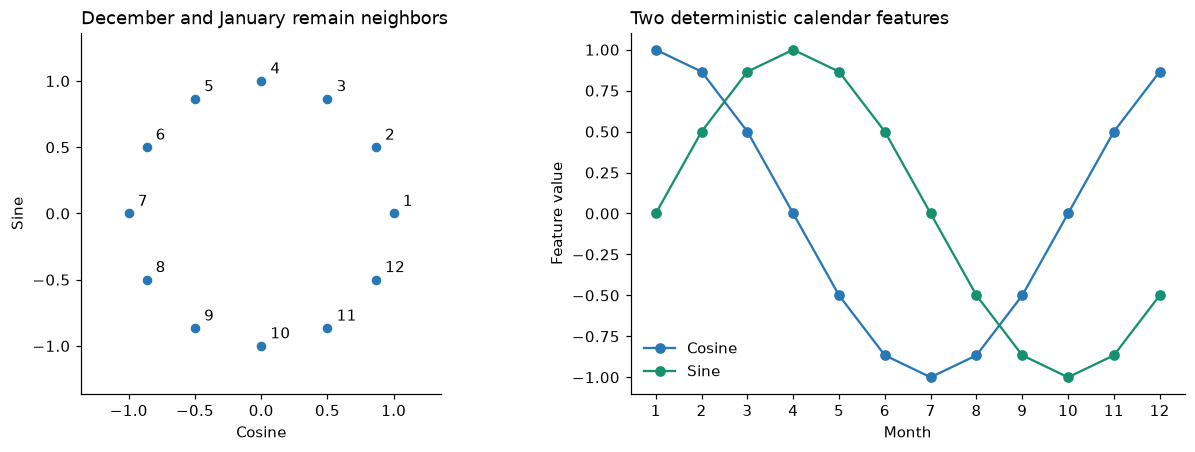

In [9]:
months = np.arange(1, 13)
cosine, sine = cyclical_encoding(months, period=12, min_value=1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
axes[0].scatter(cosine, sine, color='#2878b5', s=28)
for month, x, y in zip(months, cosine, sine):
    axes[0].annotate(str(month), (x, y), xytext=(6, 5), textcoords='offset points')
axes[0].set(xlabel='Cosine', ylabel='Sine', title='December and January remain neighbors', aspect='equal')
axes[0].margins(.18)
axes[1].plot(months, cosine, color='#2878b5', marker='o', label='Cosine')
axes[1].plot(months, sine, color='#16906f', marker='o', label='Sine')
axes[1].set(xlabel='Month', ylabel='Feature value', xticks=months, title='Two deterministic calendar features')
axes[1].legend()
plt.show()
np.testing.assert_allclose(cyclical_encoding([1, 12], period=12, min_value=1)[0], cosine[[0, 11]])

The period and phase are explicit; encoding a subset of months does not rescale the calendar. Lines connect deterministic features, not stochastic forecasts.

## See the lag boundary

In [10]:
rng = np.random.default_rng(7)
observations = pd.DataFrame({'y': np.sin(np.arange(80) / 6) + rng.normal(0, .25, 80)},
                             index=pd.date_range('2020-01-01', periods=80))
features = add_lagged_target(observations, lags=3)
display(features.head())
np.testing.assert_array_equal(features['y_t-1'], observations['y'].shift(1).dropna().loc[features.index])
calendar = add_time_features(observations)
pd.testing.assert_frame_equal(add_time_features(observations.iloc[:20]), calendar.iloc[:20])

,y,y_t-1,y_t-2,y_t-3
2020-01-04,0.256778,0.258660,0.240583,0.000308
2020-01-05,0.504702,0.256778,0.258660,0.240583
2020-01-06,0.492265,0.504702,0.256778,0.258660
2020-01-07,0.856507,0.492265,0.504702,0.256778
2020-01-08,1.254499,0.856507,0.492265,0.504702


The original y column is retained as the target. Exclude it from a contemporaneous predictor matrix. Calendar features have a fixed schema; optional TSFEL windows default to ending before the target row.

## Change one thing

Try one parameter or implementation change, rerun the relevant example, and inspect the figure or assertion. Save before exporting. The package tests provide broader regression coverage; the experiment here is intentionally small.